# Restaurant Sales Analysis & Prep Planner
Backend notebook — data analysis, demand forecasting model, and waste-minimizing prep
recommendations, built on `restaurant_sales_data.csv` (Kaggle).

**Structure**
1. Load & inspect the data
2. Planned analysis — best-sellers, busy periods, revenue trends, demand drivers
3. Demand forecasting model (Random Forest)
4. Prep recommendation engine (newsvendor model)
5. Try your own scenario

The notebook reads the data from `../data/restaurant_sales_data.csv`.

## 1. Setup & data load

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

plt.rcParams["figure.facecolor"] = "white"
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

df = pd.read_csv("../data/restaurant_sales_data.csv")
df["date"] = pd.to_datetime(df["date"], format="%m/%d/%Y")
df["weekday"] = df["date"].dt.day_name()
df["revenue"] = df["actual_selling_price"] * df["quantity_sold"]
df["cost"] = df["typical_ingredient_cost"] * df["quantity_sold"]
df["profit"] = df["revenue"] - df["cost"]

print(f"{len(df):,} rows | {df['menu_item_name'].nunique()} menu items | "
      f"{df['restaurant_id'].nunique()} restaurants")
print(f"Date range: {df['date'].min().date()} to {df['date'].max().date()}")
df.head()

10,000 rows | 14 menu items | 50 restaurants
Date range: 2024-01-01 to 2025-01-01


,date,restaurant_id,restaurant_type,menu_item_name,meal_type,key_ingredients_tags,typical_ingredient_cost,observed_market_price,actual_selling_price,quantity_sold,has_promotion,special_event,weather_condition,weekday,revenue,cost,profit
0,2024-01-01,11,Food Stall,Laksa,Lunch,"rice noodles, fish broth, tamarind, shrimp pas...",4.5,10.59,12.48,361,False,False,Sunny,Monday,4505.28,1624.5,2880.78
1,2024-01-01,7,Casual Dining,Spaghetti Carbonara,Dinner,"spaghetti, eggs, cheese, beef bacon, black pepper",9.0,26.64,60.46,105,False,False,Sunny,Monday,6348.30,945.0,5403.30
2,2024-01-01,23,Fine Dining,Beef Rendang,Dinner,"beef, coconut milk, galangal, lemongrass, spic...",9.0,49.42,80.15,36,False,False,Rainy,Monday,2885.40,324.0,2561.40
3,2024-01-01,22,Food Stall,Roti Canai,Dinner,"flour, ghee, egg, water, curry",0.8,2.04,2.48,503,False,False,Sunny,Monday,1247.44,402.4,845.04
4,2024-01-01,32,Fine Dining,Spaghetti Carbonara,Lunch,"spaghetti, eggs, cheese, beef bacon, black pepper",9.0,40.30,55.54,262,False,False,Rainy,Monday,14551.48,2358.0,12193.48


In [2]:
df.describe(include="all").T

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
date,10000,NaN,NaN,NaN,2024-07-02 13:58:48,2024-01-01 00:00:00,2024-04-02 00:00:00,2024-07-03 12:00:00,2024-10-03 00:00:00,2025-01-01 00:00:00,NaN
restaurant_id,10000.0,NaN,NaN,NaN,25.4093,1.0,13.0,25.0,38.0,50.0,14.449306
restaurant_type,10000,5,Food Stall,4362,NaN,NaN,NaN,NaN,NaN,NaN,NaN
menu_item_name,10000,14,Kaya Toast Set,1245,NaN,NaN,NaN,NaN,NaN,NaN,NaN
meal_type,10000,3,Dinner,3999,NaN,NaN,NaN,NaN,NaN,NaN,NaN
key_ingredients_tags,10000,14,"white bread, kaya, butter, soft-boiled eggs",1245,NaN,NaN,NaN,NaN,NaN,NaN,NaN
typical_ingredient_cost,10000.0,NaN,NaN,NaN,3.90345,0.8,1.2,2.8,7.0,9.0,2.874441
observed_market_price,10000.0,NaN,NaN,NaN,12.646275,1.46,4.4875,8.23,16.35,56.29,11.857813
actual_selling_price,10000.0,NaN,NaN,NaN,18.85899,1.36,6.11,11.31,26.4325,83.09,18.18718
quantity_sold,10000.0,NaN,NaN,NaN,286.0004,0.0,128.0,245.0,392.25,1668.0,217.28445


## 2. Planned analysis

Three things from the proposal: best-selling items, busy days/hours, and demand drivers
(weather, promotions, special events) — all needed before the prediction step means anything.

### 2.1 Best-selling menu items — by quantity vs. by revenue

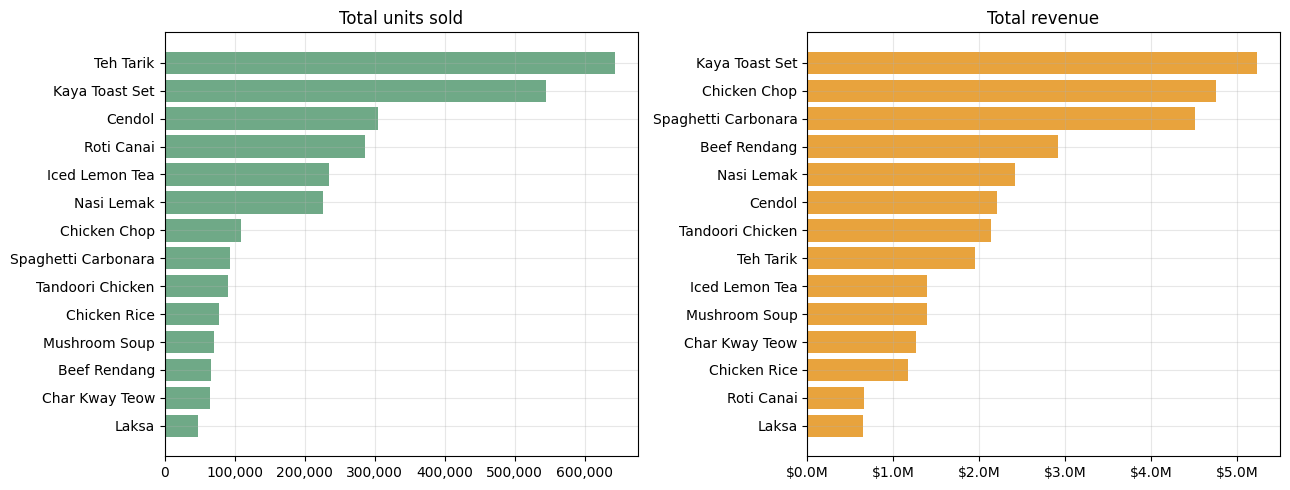

Note the gap: high-volume items (drinks, toast) aren't always the top earners —
mains like Chicken Chop and Spaghetti Carbonara punch well above their unit count.


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

top_qty = df.groupby("menu_item_name")["quantity_sold"].sum().sort_values()
top_rev = df.groupby("menu_item_name")["revenue"].sum().sort_values()

axes[0].barh(top_qty.index, top_qty.values, color="#6FA987")
axes[0].set_title("Total units sold")
axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x):,}"))

axes[1].barh(top_rev.index, top_rev.values, color="#E8A33D")
axes[1].set_title("Total revenue")
axes[1].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"${x/1e6:.1f}M"))

plt.tight_layout()
plt.show()

print("Note the gap: high-volume items (drinks, toast) aren't always the top earners —")
print("mains like Chicken Chop and Spaghetti Carbonara punch well above their unit count.")

### 2.2 Busy periods — weekday and meal period

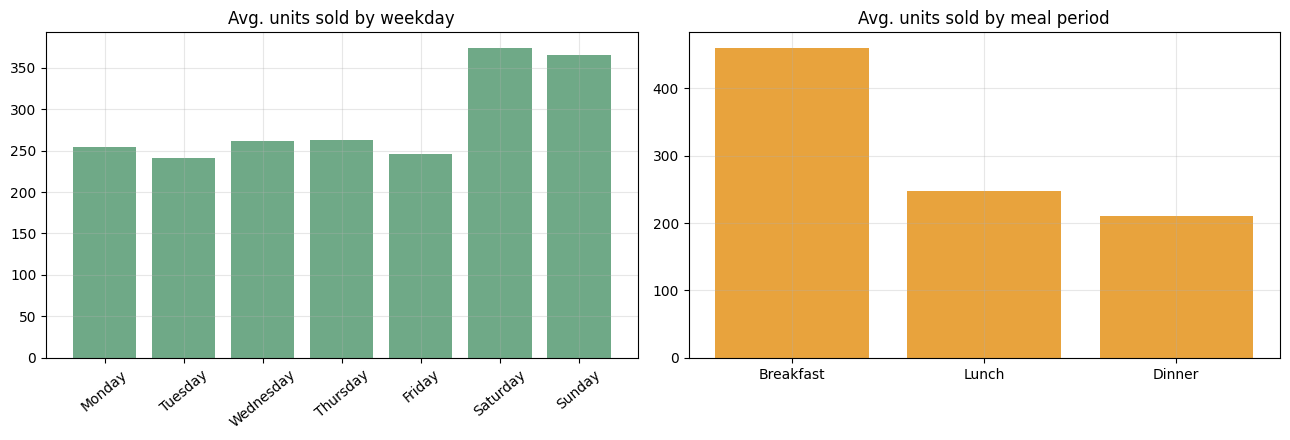

Weekend lift: 370 avg units vs. 253 on weekdays (+46%)


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

weekday_order = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
by_weekday = df.groupby("weekday")["quantity_sold"].mean().reindex(weekday_order)
by_meal = df.groupby("meal_type")["quantity_sold"].mean().sort_values(ascending=False)

axes[0].bar(by_weekday.index, by_weekday.values, color="#6FA987")
axes[0].set_title("Avg. units sold by weekday")
axes[0].tick_params(axis="x", rotation=40)

axes[1].bar(by_meal.index, by_meal.values, color="#E8A33D")
axes[1].set_title("Avg. units sold by meal period")

plt.tight_layout()
plt.show()

print(f"Weekend lift: {by_weekday[['Saturday','Sunday']].mean():.0f} avg units vs. "
      f"{by_weekday.drop(['Saturday','Sunday']).mean():.0f} on weekdays "
      f"(+{by_weekday[['Saturday','Sunday']].mean()/by_weekday.drop(['Saturday','Sunday']).mean()*100-100:.0f}%)")

### 2.3 Revenue trend over time

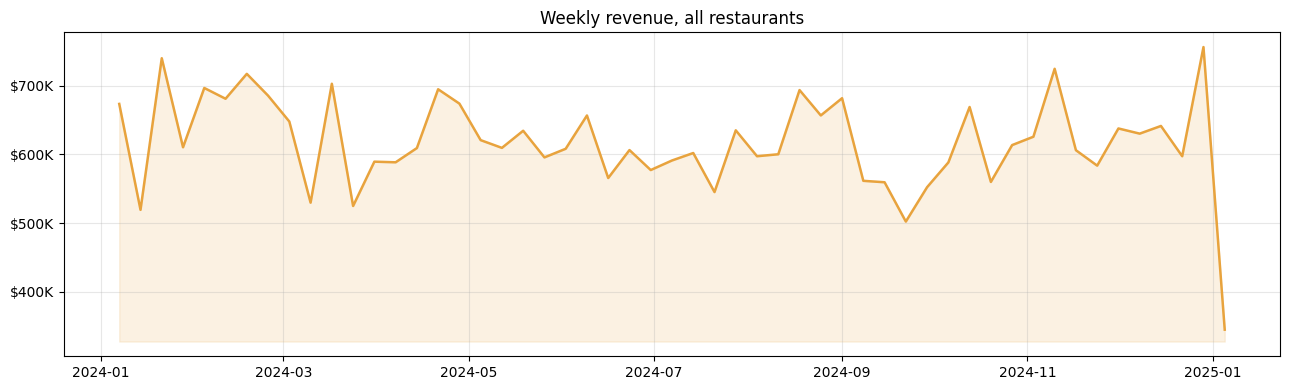

In [5]:
weekly = df.set_index("date").resample("W")["revenue"].sum()

fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(weekly.index, weekly.values, color="#E8A33D", linewidth=1.8)
ax.fill_between(weekly.index, weekly.values, weekly.min()*0.95, color="#E8A33D", alpha=0.15)
ax.set_title("Weekly revenue, all restaurants")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"${x/1e3:.0f}K"))
plt.tight_layout()
plt.show()

### 2.4 Demand drivers — weather, promotions, special events

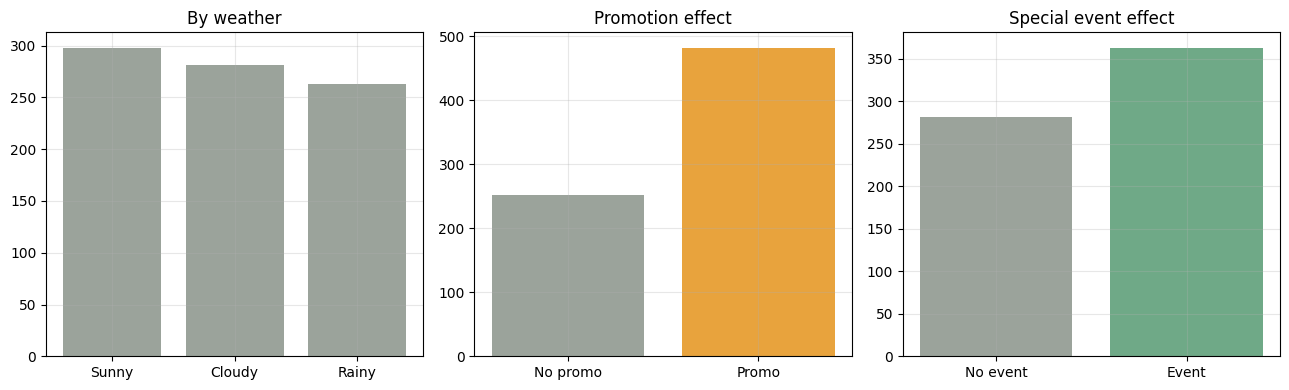

Promotions lift avg. units sold by 92%
Special events lift avg. units sold by 29%


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))

by_weather = df.groupby("weather_condition")["quantity_sold"].mean().sort_values(ascending=False)
promo = df.groupby("has_promotion")["quantity_sold"].mean()
event = df.groupby("special_event")["quantity_sold"].mean()

axes[0].bar(by_weather.index, by_weather.values, color="#9BA39B")
axes[0].set_title("By weather")

axes[1].bar(["No promo", "Promo"], [promo[False], promo[True]], color=["#9BA39B", "#E8A33D"])
axes[1].set_title("Promotion effect")

axes[2].bar(["No event", "Event"], [event[False], event[True]], color=["#9BA39B", "#6FA987"])
axes[2].set_title("Special event effect")

plt.tight_layout()
plt.show()

print(f"Promotions lift avg. units sold by {(promo[True]/promo[False]-1)*100:.0f}%")
print(f"Special events lift avg. units sold by {(event[True]/event[False]-1)*100:.0f}%")

## 3. Demand forecasting model

A Random Forest predicts `quantity_sold` from restaurant type, menu item, meal period,
weekday, weather, promotion, and special event. Evaluated against a naive baseline
(always predict the historical mean) to show it's actually learning something.

In [7]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error

CAT_FEATURES = ["restaurant_type", "menu_item_name", "meal_type", "weekday", "weather_condition"]
BOOL_FEATURES = ["has_promotion", "special_event"]
TARGET = "quantity_sold"

X = df[CAT_FEATURES + BOOL_FEATURES]
y = df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

pre = ColumnTransformer(
    transformers=[("cat", OneHotEncoder(handle_unknown="ignore"), CAT_FEATURES)],
    remainder="passthrough",
)
model = RandomForestRegressor(n_estimators=300, max_depth=14, min_samples_leaf=3,
                               random_state=42, n_jobs=-1)
pipe = Pipeline([("pre", pre), ("model", model)])
pipe.fit(X_train, y_train)

preds = pipe.predict(X_test)
mae = mean_absolute_error(y_test, preds)
rmse = mean_squared_error(y_test, preds) ** 0.5
baseline_mae = mean_absolute_error(y_test, [y_train.mean()] * len(y_test))

print(f"Model MAE:            {mae:.1f} units")
print(f"Model RMSE:           {rmse:.1f} units")
print(f"Naive baseline MAE:   {baseline_mae:.1f} units")
print(f"Improvement vs naive: {(1 - mae/baseline_mae)*100:.1f}%")

Model MAE:            83.0 units
Model RMSE:           106.0 units
Naive baseline MAE:   166.3 units
Improvement vs naive: 50.1%


### 3.1 What drives the model's predictions

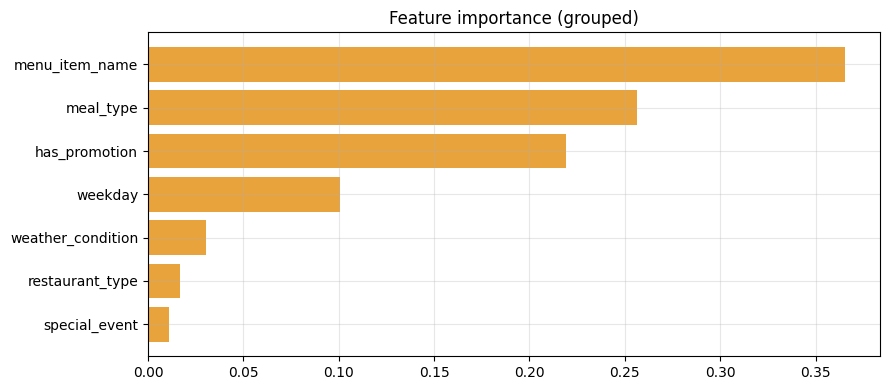

In [8]:
ohe = pipe.named_steps["pre"].named_transformers_["cat"]
feature_names = list(ohe.get_feature_names_out(CAT_FEATURES)) + BOOL_FEATURES
importances = pipe.named_steps["model"].feature_importances_

# roll one-hot columns back up to their source feature for a readable chart
imp_by_source = {}
for name, imp in zip(feature_names, importances):
    source = name.split("_")[0] if name not in BOOL_FEATURES else name
    for cat in CAT_FEATURES:
        if name.startswith(cat + "_"):
            source = cat
            break
    imp_by_source[source] = imp_by_source.get(source, 0) + imp

imp_series = pd.Series(imp_by_source).sort_values()
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(imp_series.index, imp_series.values, color="#E8A33D")
ax.set_title("Feature importance (grouped)")
plt.tight_layout()
plt.show()

## 4. Prep recommendation engine

The raw forecast alone isn't the right prep number — it minimizes *average* error, not
cost. This uses a **newsvendor model**: prep is pushed above the forecast by an amount
that depends on the item's economics —

- **Overage cost** (prepping one unit too many) = ingredient cost, wasted
- **Underage cost** (prepping one unit too few) = margin, lost to a sellout

`critical_ratio = underage / (underage + overage)` gives the demand-distribution quantile
to prep to. High-margin items get a bigger buffer; cheap staples get almost none.

In [9]:
from scipy.stats import norm

item_econ = df.groupby("menu_item_name").agg(
    ingredient_cost=("typical_ingredient_cost", "mean"),
    selling_price=("actual_selling_price", "mean"),
)
item_econ["margin"] = item_econ["selling_price"] - item_econ["ingredient_cost"]

# per-item residual std, so the buffer is sized per item rather than with one global number
all_preds = pipe.predict(df[CAT_FEATURES + BOOL_FEATURES])
df["_resid"] = df[TARGET].values - all_preds
residual_std = df.groupby("menu_item_name")["_resid"].std().to_dict()

def recommend_prep(restaurant_type, menu_item_name, meal_type, weekday,
                    weather_condition, has_promotion, special_event):
    row = pd.DataFrame([{
        "restaurant_type": restaurant_type, "menu_item_name": menu_item_name,
        "meal_type": meal_type, "weekday": weekday,
        "weather_condition": weather_condition,
        "has_promotion": has_promotion, "special_event": special_event,
    }])
    predicted = float(pipe.predict(row)[0])

    econ = item_econ.loc[menu_item_name]
    overage, underage = econ["ingredient_cost"], econ["margin"]
    critical_ratio = min(max(underage / (underage + overage), 0.5), 0.97)

    std = residual_std.get(menu_item_name, predicted * 0.15)
    z = norm.ppf(critical_ratio)
    recommended = max(0, predicted + z * std)

    return {
        "item": menu_item_name,
        "predicted_demand": round(predicted, 1),
        "recommended_prep": round(recommended, 1),
        "buffer_units": round(recommended - predicted, 1),
        "critical_ratio": round(critical_ratio, 3),
        "unit_margin": round(underage, 2),
        "unit_ingredient_cost": round(overage, 2),
    }

# sample recommendations across a few services
samples = [
    dict(restaurant_type="Food Stall", menu_item_name="Teh Tarik", meal_type="Breakfast",
         weekday="Saturday", weather_condition="Sunny", has_promotion=False, special_event=False),
    dict(restaurant_type="Casual Dining", menu_item_name="Chicken Chop", meal_type="Dinner",
         weekday="Friday", weather_condition="Rainy", has_promotion=True, special_event=False),
    dict(restaurant_type="Fine Dining", menu_item_name="Beef Rendang", meal_type="Dinner",
         weekday="Sunday", weather_condition="Cloudy", has_promotion=False, special_event=True),
]
pd.DataFrame([recommend_prep(**s) for s in samples])

,item,predicted_demand,recommended_prep,buffer_units,critical_ratio,unit_margin,unit_ingredient_cost
0,Teh Tarik,871.2,942.4,71.3,0.715,2.26,0.9
1,Chicken Chop,217.4,299.4,82.0,0.831,39.26,8.0
2,Beef Rendang,142.7,212.9,70.3,0.813,39.14,9.0


## 5. Try your own scenario

Edit the arguments below and re-run the cell to get a prep recommendation for any
restaurant type / item / meal / weekday / weather / promo / event combination.
Valid values are listed in the printed menu below the cell.

In [10]:
print("restaurant_type:", sorted(df["restaurant_type"].unique()))
print("menu_item_name: ", sorted(df["menu_item_name"].unique()))
print("meal_type:      ", sorted(df["meal_type"].unique()))
print("weekday:        ", weekday_order)
print("weather_condition:", sorted(df["weather_condition"].unique()))

restaurant_type: ['Cafe', 'Casual Dining', 'Fine Dining', 'Food Stall', 'Kopitiam']
menu_item_name:  ['Beef Rendang', 'Cendol', 'Char Kway Teow', 'Chicken Chop', 'Chicken Rice', 'Iced Lemon Tea', 'Kaya Toast Set', 'Laksa', 'Mushroom Soup', 'Nasi Lemak', 'Roti Canai', 'Spaghetti Carbonara', 'Tandoori Chicken', 'Teh Tarik']
meal_type:       ['Breakfast', 'Dinner', 'Lunch']
weekday:         ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
weather_condition: ['Cloudy', 'Rainy', 'Sunny']


In [11]:
recommend_prep(
    restaurant_type="Kopitiam",
    menu_item_name="Kaya Toast Set",
    meal_type="Breakfast",
    weekday="Saturday",
    weather_condition="Sunny",
    has_promotion=False,
    special_event=False,
)

{'item': 'Kaya Toast Set',
 'predicted_demand': 495.5,
 'recommended_prep': np.float64(560.2),
 'buffer_units': np.float64(64.7),
 'critical_ratio': np.float64(0.722),
 'unit_margin': np.float64(7.27),
 'unit_ingredient_cost': np.float64(2.8)}

## 6. Export

Save the trained pipeline so it can be loaded elsewhere (an API, a script, another
notebook) without retraining.

In [12]:
import joblib

joblib.dump(pipe, "demand_model.joblib")
item_econ.to_csv("item_economics.csv")
print("Saved demand_model.joblib and item_economics.csv")

Saved demand_model.joblib and item_economics.csv
